# Model Results Analysis

Compare validation metrics across BirdNET experiments and inspect held-out test metrics for the selected model.

In [14]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

def find_project_root(start=None):
    path = Path(start or Path.cwd()).resolve()
    for candidate in [path, *path.parents]:
        if (candidate / "workspace").exists() and (candidate / "scripts").exists():
            return candidate
    raise FileNotFoundError("Could not find project root containing workspace/ and scripts/. Run this notebook from inside the StromPetrels project.")

PROJECT_ROOT = find_project_root()
MODELS = PROJECT_ROOT / "workspace" / "models"
SUMMARY = MODELS / "birdnet_experiment_summary.csv"

pd.set_option("display.max_columns", 50)
SUMMARY

WindowsPath('D:/Documents/StromPetrels/workspace/models/birdnet_experiment_summary.csv')

## Validation Experiment Summary

,experiment,learning_rate,hidden_units,dropout,precision_0_5,recall_0_5,f1_0_5,precision_opt,recall_opt,f1_opt,auprc,auroc,optimal_threshold,true_positives,false_positives,true_negatives,false_negatives
3,storm_petrel_classifier_C,0.00010,256,0.3,0.9375,1.0,0.9677,0.9733,0.9733,0.9733,0.9974,0.9973,0.85,73,2,73,2
2,storm_petrel_classifier_B,0.00005,256,0.2,0.9375,1.0,0.9677,0.9375,1.0000,0.9677,0.9972,0.9972,0.30,75,5,70,0
4,storm_petrel_classifier_D,0.00005,512,0.3,0.9259,1.0,0.9615,0.9375,1.0000,0.9677,0.9970,0.9970,0.55,75,5,70,0
1,storm_petrel_classifier_A,0.00010,0,0.0,0.9375,1.0,0.9677,0.9494,1.0000,0.9740,0.9957,0.9957,0.70,75,4,71,0
0,storm_petrel_classifier_baseline,0.00010,0,0.0,0.9146,1.0,0.9554,0.9494,1.0000,0.9740,0.9910,0.9918,0.65,75,4,71,0


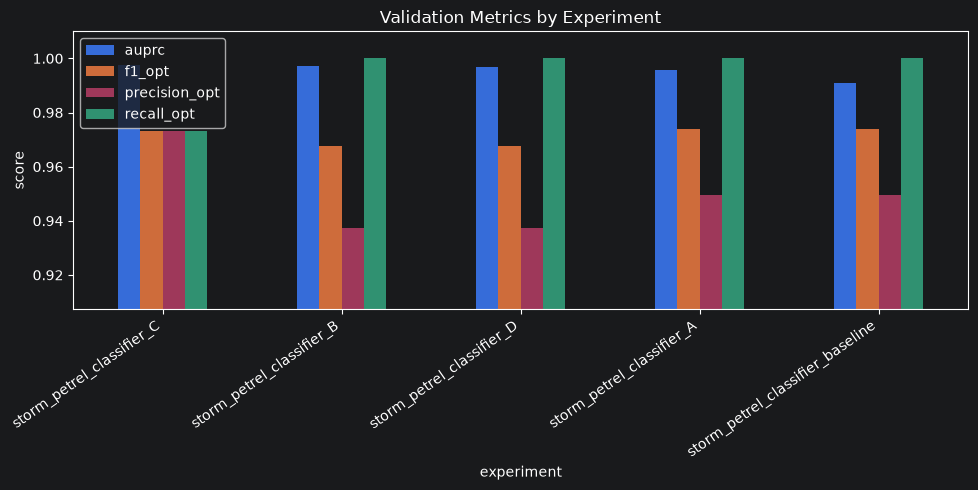

In [15]:
if not SUMMARY.exists():
    raise FileNotFoundError(f"Missing experiment summary: {SUMMARY}. Run scripts/results_analysis/summarize_birdnet_experiments.py first.")

summary = pd.read_csv(SUMMARY)
metric_cols = ["precision_0_5", "recall_0_5", "f1_0_5", "precision_opt", "recall_opt", "f1_opt", "auprc", "auroc"]
summary[metric_cols] = summary[metric_cols].apply(pd.to_numeric)
summary = summary.sort_values("auprc", ascending=False)
display(summary)

plot_df = summary.set_index("experiment")[["auprc", "f1_opt", "precision_opt", "recall_opt"]]
ax = plot_df.plot(kind="bar", figsize=(10, 5))
y_min = max(0, plot_df.min().min() - 0.03)
ax.set_ylim(y_min, 1.01)
ax.set_title("Validation Metrics by Experiment")
ax.set_ylabel("score")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

## Held-Out Test Metrics

In [16]:
test_metrics_path = MODELS / "storm_petrel_classifier_C_test_metrics.csv"
test_metrics = pd.read_csv(test_metrics_path)
display(test_metrics.T.rename(columns={0: "value"}))

,value
model,D:\Documents\StromPetrels\workspace\models\sto...
data_dir,D:\Documents\StromPetrels\workspace\birdnet_da...
samples,150
precision_0_5,0.961
recall_0_5,0.9867
f1_0_5,0.9737
precision_opt,0.961
recall_opt,0.9867
f1_opt,0.9737
auprc,0.9897


Use validation metrics to select a model. Use test metrics once, after selection, to estimate final performance.